In [1]:
import os, glob
import numpy as np
import pandas as pd
from matplotlib import pyplot as plt
from tqdm import tqdm

In [2]:

levels = ['32m', '80m'] #, '47m', '80m', '140m', '200m', '280m']
data_path = r"D:\!Work\IFA\!data\Urban_fluxes_NE\raw\Beijing\*\Xianghe tower"

df4levels = {}

for level in levels:
    files = glob.glob(os.path.join(data_path + '\\' + level, "*.dat"))
    df = pd.DataFrame()
    for file in tqdm(files):
        cur_df = pd.read_csv(file, header=1, skiprows=range(2,4), parse_dates=['TIMESTAMP'], index_col = 'TIMESTAMP')
        df = pd.concat((df, cur_df))

    #df['Cp']        = pd.to_numeric(df['Cp'], errors='coerce')
    #df['rho_a_Avg'] = pd.to_numeric(df['rho_a_Avg'], errors='coerce')
    #df['rho_d_Avg'] = pd.to_numeric(df['rho_d_Avg'], errors='coerce')
    df = df.apply(pd.to_numeric, errors='coerce')

    df['H'] = df['wTs_Cov_R_F_SND']*df['Cp']*df['rho_a_Avg']
    df['LE'] = df['wH2O_Cov_R_F']*(2.501*10**6)/1000
    df['Tau'] = df['rho_d_Avg']*df['u_star_R']**2

    df4levels[level] = df

100%|██████████| 2208/2208 [00:14<00:00, 149.55it/s]


In [3]:
df.columns

Index(['RECORD', 'UxUy_Cov', 'UxUz_Cov', 'UyUz_Cov', 'TsUx_Cov', 'TsUy_Cov',
       'TsUz_Cov', 'u_star_R', 'u_Avg_R', 'u_Std_R', 'v_Avg_R', 'v_Std_R',
       'w_Avg_R', 'w_Std_R', 'uv_Cov_R', 'uw_Cov_R', 'vw_Cov_R', 'uTs_Cov_R',
       'vTs_Cov_R', 'wTs_Cov_R', 'uw_Cov_R_F', 'vw_Cov_R_F', 'wTs_Cov_R_F',
       'wTs_Cov_R_F_SND', 'sonic_samples_Tot', 'no_sonic_head_Tot',
       'no_new_sonic_data_Tot', 'sig_error_Tot', 'sonic_amp_l_f_Tot',
       'sonic_amp_h_f_Tot', 'sonic_sig_lck_f_Tot', 'sonic_del_T_f_Tot',
       'UxCO2_Cov', 'UyCO2_Cov', 'UzCO2_Cov', 'UxH2O_Cov', 'UyH2O_Cov',
       'UzH2O_Cov', 'uCO2_Cov_R', 'vCO2_Cov_R', 'wCO2_Cov_R', 'uH2O_Cov_R',
       'vH2O_Cov_R', 'wH2O_Cov_R', 'wCO2_Cov_R_F', 'wH2O_Cov_R_F',
       'CO2_E_WPL_R_F', 'CO2_T_WPL_R_F', 'H2O_E_WPL_R_F', 'H2O_T_WPL_R_F',
       'CO2_samples_Tot', 'H2O_samples_Tot', 'no_new_irga_data_Tot',
       'irga_sync_f_Tot', 'no_new_data_LI7500_Tot', 'sig_error_LI7500_Tot',
       'agc_Avg', 'agc_thrshld_excded_Tot', 'alph

<Axes: xlabel='TIMESTAMP'>

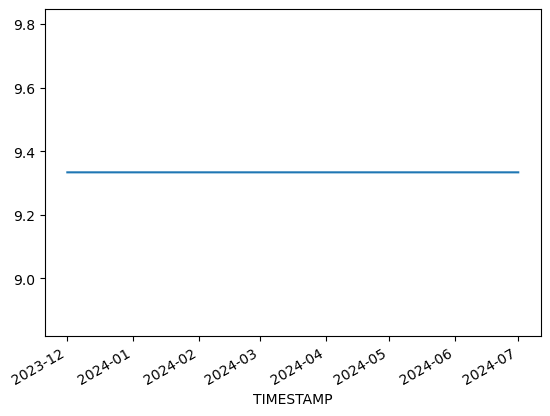

In [4]:
df['z'].plot()

In [5]:
%matplotlib qt
(df4levels['32m']['wCO2_Cov_R'] * (10**-3) * 0.0289647 * 10**6).plot()

<Axes: xlabel='TIMESTAMP'>

In [6]:
#df['u_Avg_R'].plot()
#df['w_Avg_R'].plot()

In [7]:
df['H'].plot()

<Axes: xlabel='TIMESTAMP'>

In [8]:
df['wH2O_Cov_R'].plot()
df['wH2O_Cov_R_F'].plot()

<Axes: xlabel='TIMESTAMP'>

In [9]:
%matplotlib qt
plt.figure()
plt.plot(df['wTs_Cov_R'])
plt.plot(df['wTs_Cov_R_F'])
plt.plot(df['wTs_Cov_R_F_SND'])

In [10]:
export_dir = "D:/!Work/IFA/!data/Urban_fluxes_NE/processed/Beijing" 

time_shift = pd.Timedelta(8, 'h')

os.makedirs(export_dir, exist_ok=True)

for level in df4levels.keys():
    df4level = df4levels[level]
    df2export = df4level[['H', 'LE', 'Tau', 'u_star_R', 'rho_a_Avg', 'u_Avg_R']] #, 'wind_speed', 'wind_dir']] #, 'uz', 't', 'r', 'P', 'ro', 'u', 'v', 'w', 'V', 'D', 'alfa']]
    df2export.index.set_names('datetime_utc', inplace=True)
    df2export = df2export.rename(columns = {'H': 'Qh',
                                            'LE': 'Qle',
                                            'Tau': 'Qtau',
                                            'u_star_R':'Ustar', 
                                            #'air_temperature': 'T_air',
                                            #'RH': 'RH_air',
                                            #'air_pressure': 'P_air',
                                            'rho_a_Avg': 'Rho_air',
                                            'u_Avg_R':'Wind_vel',
                                            })

    df2export.index = df2export.index - time_shift
    df2export.to_csv(export_dir + '/' + 'Xianghe' + '_' + level +  '.csv')

    